# Basic Arithmetic and Algebra

R is, among other things, a powerful calculator. In this lesson we review arithmetic operators, the order of operations, and use R to work with **algebra**: evaluating expressions, solving linear and quadratic equations, and solving systems of equations.

In [1]:
# Notebook setup: wide, readable figures with an opaque white background.
# (Without the hook, base-R plots render with a transparent background and
#  the black axes/labels disappear on dark-themed notebook viewers.)
options(repr.plot.width = 10, repr.plot.height = 6, repr.plot.res = 100)
setHook("before.plot.new", function() par(bg = "white"))

## 1. Arithmetic Operators

| Operator | Meaning | Example |
|---|---|---|
| `+`, `-`, `*`, `/` | basic arithmetic | `10 / 3` → 3.333 |
| `^` | exponentiation | `2^10` → 1024 |
| `%%` | modulus (remainder) | `10 %% 3` → 1 |
| `%/%` | integer division | `10 %/% 3` → 3 |

**Order of operations** follows standard math rules (PEMDAS): parentheses → exponents → multiplication/division → addition/subtraction.

In [2]:
a <- 10
b <- 3

print(paste("Sum:", a + b))
print(paste("Difference:", a - b))
print(paste("Product:", a * b))
print(paste("Quotient:", round(a / b, 4)))
print(paste("Power:", a^b))
print(paste("Remainder:", a %% b))
print(paste("Integer Division:", a %/% b))

[1] "Sum: 13"


[1] "Difference: 7"


[1] "Product: 30"


[1] "Quotient: 3.3333"


[1] "Power: 1000"


[1] "Remainder: 1"


[1] "Integer Division: 3"


In [3]:
# Order of operations matters
cat("2 + 3 * 4     =", 2 + 3 * 4, "\n")
cat("(2 + 3) * 4   =", (2 + 3) * 4, "\n")
cat("-2^2          =", -2^2, "  (exponent binds tighter than unary minus!)\n")
cat("(-2)^2        =", (-2)^2, "\n")

# Floating-point surprise
cat("0.1 + 0.2 == 0.3       :", 0.1 + 0.2 == 0.3, "\n")
cat("isTRUE(all.equal(...)) :", isTRUE(all.equal(0.1 + 0.2, 0.3)), "\n")

2 + 3 * 4     = 14 


(2 + 3) * 4   = 20 


-2^2          = -4   (exponent binds tighter than unary minus!)


(-2)^2        = 4 


0.1 + 0.2 == 0.3       : FALSE 


isTRUE(all.equal(...)) : TRUE 


*Insight: Computers store decimals in binary, so `0.1 + 0.2` is not exactly `0.3`. Never compare decimals with `==`; use `all.equal()` (or a tolerance) instead.*

## 2. Verifying Algebraic Identities

Algebraic identities must hold for **every** value. We can check them numerically on many random values at once — vectorisation makes this a one-liner:

$$
(a+b)^2 = a^2 + 2ab + b^2, \qquad a^2 - b^2 = (a-b)(a+b)
$$

In [4]:
set.seed(1)
a <- runif(1000, -10, 10)
b <- runif(1000, -10, 10)

cat("(a+b)^2 == a^2 + 2ab + b^2 for all 1000 pairs:", isTRUE(all.equal((a + b)^2, a^2 + 2*a*b + b^2)), "\n")
cat("a^2 - b^2 == (a-b)(a+b)    for all 1000 pairs:", isTRUE(all.equal(a^2 - b^2, (a - b) * (a + b))), "\n")
cat("(a+b)^2 == a^2 + b^2  ? (a common mistake)   :", isTRUE(all.equal((a + b)^2, a^2 + b^2)), "\n")

(a+b)^2 == a^2 + 2ab + b^2 for all 1000 pairs: TRUE 


a^2 - b^2 == (a-b)(a+b)    for all 1000 pairs: TRUE 


(a+b)^2 == a^2 + b^2  ? (a common mistake)   : FALSE 


## 3. Linear Equations

A linear equation $y = mx + c$ has slope $m$ and intercept $c$. Solving $mx + c = 0$ gives $x = -c/m$.

[1] "Values of y for x = 1:5:"


[1]  7  9 11 13 15


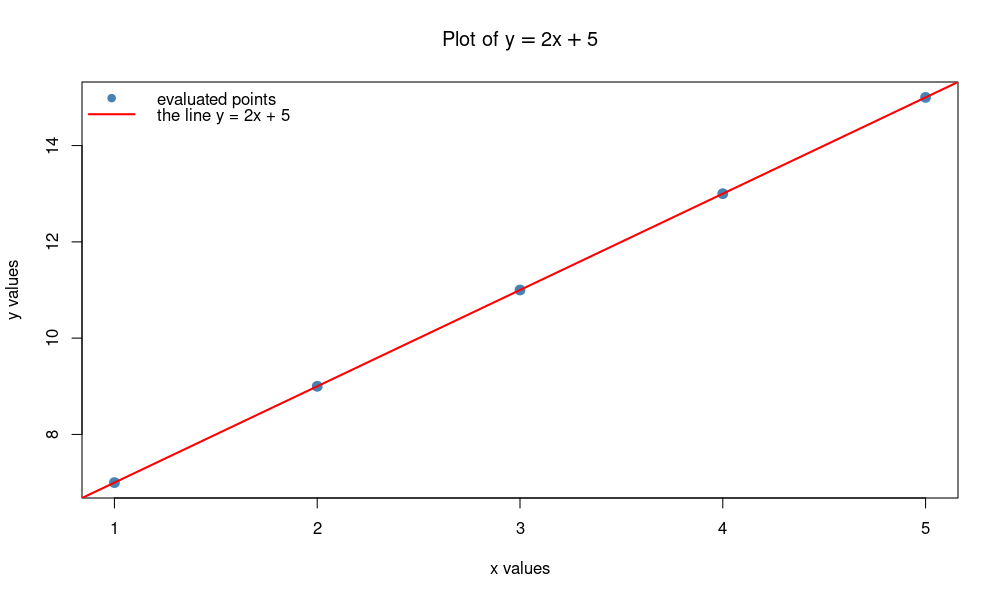

In [5]:
x <- 1:5
y <- 2 * x + 5   # linear equation: y = 2x + 5

print("Values of y for x = 1:5:")
print(y)

plot(x, y, pch = 19, col = "steelblue", cex = 1.3,
     main = expression("Plot of" ~ y == 2*x + 5),
     xlab = "x values", ylab = "y values")
abline(a = 5, b = 2, col = "red", lwd = 2)
legend("topleft", c("evaluated points", "the line y = 2x + 5"),
       col = c("steelblue", "red"), pch = c(19, NA), lty = c(NA, 1), lwd = c(NA, 2), bty = "n")

## 4. Quadratic Equations

For $ax^2 + bx + c = 0$ the roots are

$$
x = \frac{-b \pm \sqrt{b^2 - 4ac}}{2a}
$$

The **discriminant** $\Delta = b^2 - 4ac$ tells us how many real roots exist: two ($\Delta>0$), one ($\Delta=0$) or none ($\Delta<0$). R's `polyroot()` solves any polynomial (coefficients in *increasing* order of power).

Roots via formula   : -2 3 


Roots via polyroot():  3 -2 


Check f(roots)      : 0 0 


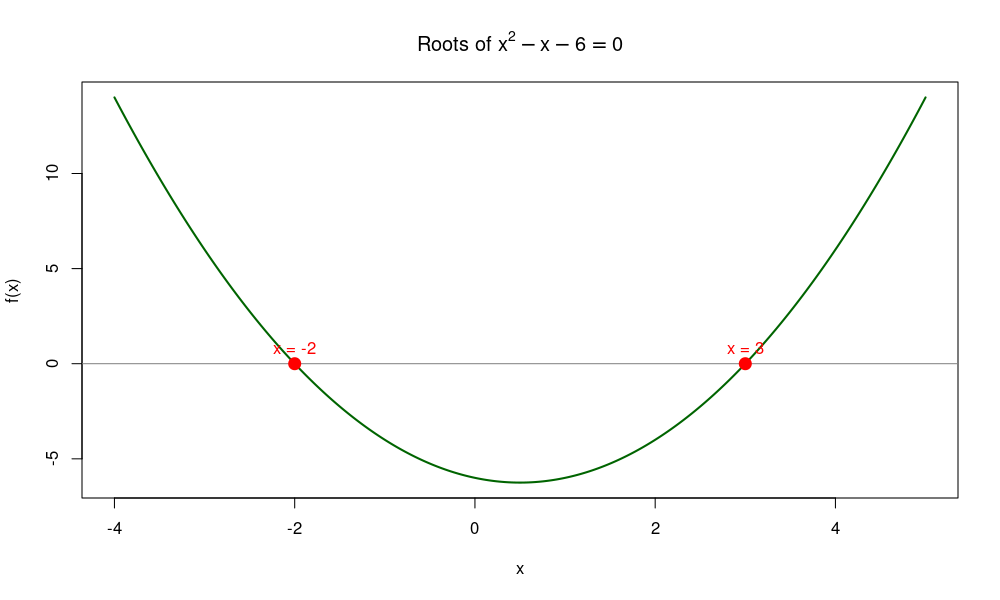

In [6]:
solve_quadratic <- function(a, b, c) {
  disc <- b^2 - 4 * a * c
  if (disc < 0) return(numeric(0))
  sort(unique((-b + c(-1, 1) * sqrt(disc)) / (2 * a)))
}

# x^2 - x - 6 = 0  ->  (x - 3)(x + 2) = 0
roots <- solve_quadratic(1, -1, -6)
cat("Roots via formula   :", roots, "\n")
cat("Roots via polyroot(): ", Re(polyroot(c(-6, -1, 1))), "\n")
cat("Check f(roots)      :", roots^2 - roots - 6, "\n")

xs <- seq(-4, 5, length.out = 300)
plot(xs, xs^2 - xs - 6, type = "l", lwd = 2, col = "darkgreen",
     main = expression("Roots of" ~ x^2 - x - 6 == 0), xlab = "x", ylab = "f(x)")
abline(h = 0, col = "grey50")
points(roots, c(0, 0), pch = 19, col = "red", cex = 1.6)
text(roots, 0, paste("x =", roots), pos = 3, col = "red")

## 5. Systems of Linear Equations

Two equations, two unknowns:

$$
\begin{cases} 2x + 3y = 13 \\ x - y = -1 \end{cases}
\quad\Longleftrightarrow\quad
\underbrace{\begin{pmatrix} 2 & 3 \\ 1 & -1 \end{pmatrix}}_{A}
\begin{pmatrix} x \\ y \end{pmatrix} =
\underbrace{\begin{pmatrix} 13 \\ -1 \end{pmatrix}}_{b}
$$

`solve(A, b)` finds the solution. Geometrically, it's the point where the two lines cross.

Solution: x = 2 , y = 3 


Check A %*% sol = 13 -1 


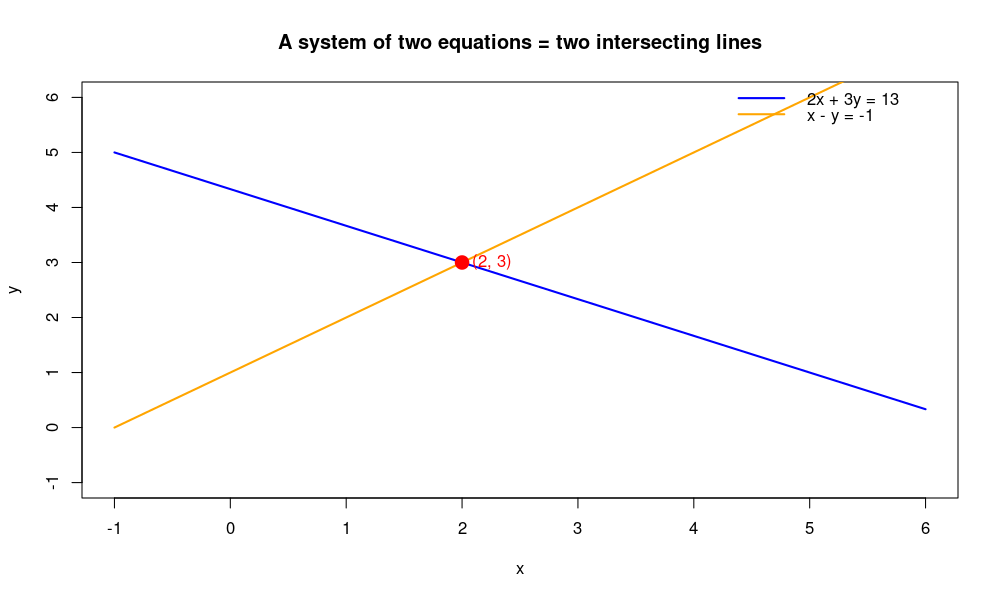

In [7]:
A <- matrix(c(2, 3,
              1, -1), nrow = 2, byrow = TRUE)
b <- c(13, -1)
sol <- solve(A, b)
cat("Solution: x =", sol[1], ", y =", sol[2], "\n")
cat("Check A %*% sol =", A %*% sol, "\n")

xs <- seq(-1, 6, length.out = 100)
plot(xs, (13 - 2 * xs) / 3, type = "l", lwd = 2, col = "blue", ylim = c(-1, 6),
     main = "A system of two equations = two intersecting lines", xlab = "x", ylab = "y")
lines(xs, xs + 1, lwd = 2, col = "orange")
points(sol[1], sol[2], pch = 19, cex = 1.8, col = "red")
text(sol[1], sol[2], sprintf("(%g, %g)", sol[1], sol[2]), pos = 4, col = "red")
legend("topright", c("2x + 3y = 13", "x - y = -1"), col = c("blue", "orange"), lwd = 2, bty = "n")

*Insight: The same `solve()` call scales to thousands of equations. That is exactly how linear regression is computed under the hood (Lesson 20): the normal equations $X^TX\beta = X^Ty$ are just a big linear system.*

## Real-World Use Case or Analogy

- **Arithmetic**: adding or subtracting items in a shopping cart.
- **Linear equation**: a taxi fare — a fixed starting fee (intercept) plus a price per kilometre (slope): $y = 2x + 5$.
- **Quadratic equation**: the path of a thrown ball — the roots tell you where it leaves and hits the ground.
- **System of equations**: two friends' receipts — "2 coffees + 3 bagels = 13 TL" and "a coffee costs 1 TL less than a bagel". Solving the system tells you the price of each item.